# 01 · Post Performance Model

**Goal:** learn from past post results (impressions, likes, comments, shares, clicks, saves) so the agent can
1. **rank** new AI-written drafts before you review them, and
2. **feed insights back** into the AI writer's prompt, so future posts improve.

**Data:** starts with synthetic sample data (`data/sample/`). Swap in your real data by putting analytics exports in
`data/raw/` or turning on the Meta API below. The rest of the notebook stays the same.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

from social_agent import synthetic
from social_agent.features import FEATURES, TARGET, DAYS, build_features, drafts_to_frame
from social_agent.loaders import MetaClient, load_folder
from social_agent.schema import combine
from social_agent import model as m

load_dotenv(ROOT / ".env")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

## 1. Load data

Pick your sources. While you have no real data, keep `USE_SAMPLE = True`.
- **CSV exports:** drop files into `data/raw/` (put `linkedin`, `facebook` or `instagram` in each file name).
- **Meta API:** fill in `.env` (see `.env.example`) and set `USE_META_API = True`.

In [2]:
USE_SAMPLE = True
USE_CSV_EXPORTS = True
USE_META_API = False

frames = []
if USE_SAMPLE:
    frames.append(synthetic.generate())
if USE_CSV_EXPORTS:
    raw = load_folder(ROOT / "data/raw")
    if not raw.empty:
        frames.append(raw)
if USE_META_API:
    frames.append(MetaClient().fetch_all(max_posts=200))

posts = combine(*frames)
posts.to_csv(ROOT / "data/processed/posts.csv", index=False)
print(f"{len(posts)} posts  |  sources: {posts['source'].value_counts().to_dict()}")
posts.head()

450 posts  |  sources: {'sample': 450}


,post_id,platform,posted_at,text,media_type,impressions,reach,likes,comments,shares,clicks,saves,source
0,sample_0413,facebook,2025-05-29 19:20:00,"🔥 A simple checklist for your next campaign. Limited spots, don't miss it. E...",image,1653,1316,48,11,5,13,NaN,sample
1,sample_0281,instagram,2025-05-30 12:08:00,✨ 🙌 A new study on how people shop online. I've made this mistake myself. Co...,carousel,858,666,146,26,15,8,15.0,sample
2,sample_0215,instagram,2025-05-31 09:45:00,🙌 The biggest mistake I see in social media marketing. I've made this mistak...,image,450,270,44,3,5,0,10.0,sample
3,sample_0005,facebook,2025-06-03 08:53:00,💡 The biggest mistake I see in social media marketing. Believe in the proces...,image,500,421,5,1,2,0,NaN,sample
4,sample_0250,linkedin,2025-06-03 18:03:00,"👇 See you at the marketing conference this weekend. Honestly, I was skeptica...",none,2213,1533,75,17,7,15,NaN,sample


## 2. Features

Each post becomes numbers the model can learn from: timing, format, text style, topic and tone.

**Target = engagement rate** = (likes + comments + shares + clicks + saves) / impressions.
We use a rate, not raw likes, because raw likes mostly depend on how many people saw the post.

In [3]:
df = build_features(posts)
df[["platform", "posted_at", "media_type", "topic", "tone", "word_count", "hashtag_count",
    "has_question", "has_cta", "has_link", TARGET]].head(8)

,platform,posted_at,media_type,topic,tone,word_count,hashtag_count,has_question,has_cta,has_link,engagement_rate
0,facebook,2025-05-29 19:20:00,image,tips,promotional,98,5,1,1,1,0.046582
1,instagram,2025-05-30 12:08:00,carousel,tips,personal,38,6,1,1,0,0.244755
2,instagram,2025-05-31 09:45:00,image,tips,personal,25,1,1,0,0,0.137778
3,facebook,2025-06-03 08:53:00,image,tips,personal,34,1,0,1,0,0.016000
4,linkedin,2025-06-03 18:03:00,none,event,personal,70,2,0,0,0,0.051514
5,linkedin,2025-06-07 09:36:00,none,customer_story,inspirational,24,3,1,1,0,0.036932
6,facebook,2025-06-09 14:23:00,video,industry_news,personal,71,2,0,1,0,0.033149
7,facebook,2025-06-10 22:05:00,video,tips,personal,57,4,0,1,1,0.029577


## 3. Explore: what does engagement look like?

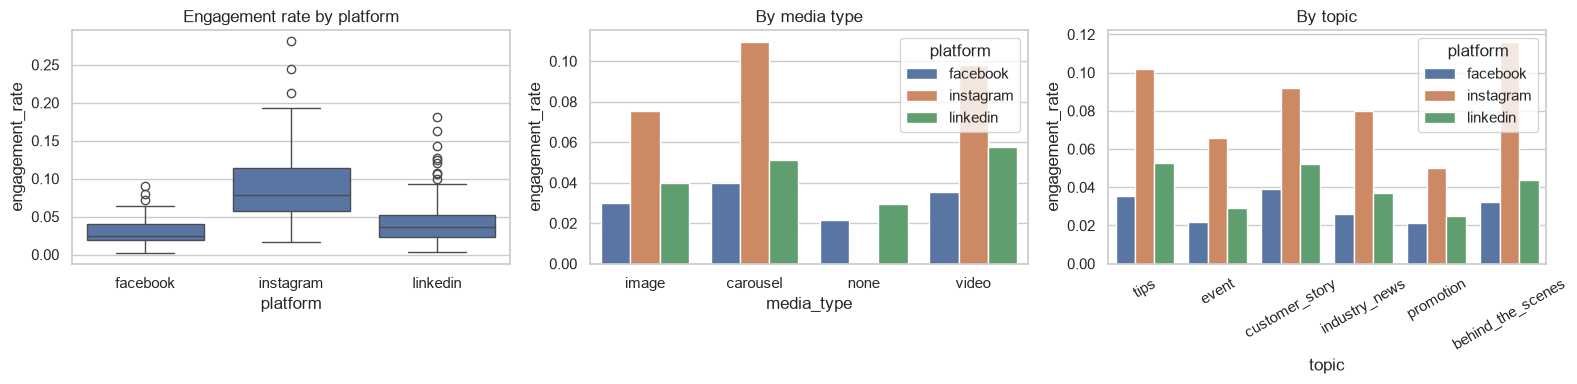

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x="platform", y=TARGET, ax=axes[0]).set_title("Engagement rate by platform")
sns.barplot(data=df, x="media_type", y=TARGET, hue="platform", ax=axes[1], errorbar=None).set_title("By media type")
sns.barplot(data=df, x="topic", y=TARGET, hue="platform", ax=axes[2], errorbar=None).set_title("By topic")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()

Text(0.5, 1.0, 'LinkedIn engagement rate by day and time')

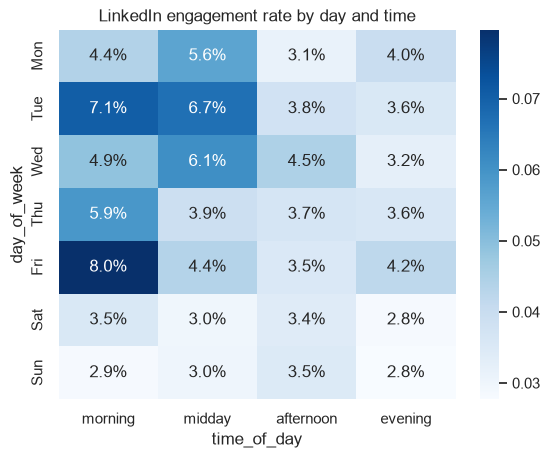

In [5]:
# When do LinkedIn posts do best? (average engagement rate by day and time of day)
li = df[df["platform"] == "linkedin"]
heat = li.pivot_table(index="day_of_week", columns="time_of_day", values=TARGET, aggfunc="mean")
heat = heat.reindex(index=DAYS, columns=["morning", "midday", "afternoon", "evening"])
sns.heatmap(heat, annot=True, fmt=".1%", cmap="Blues").set_title("LinkedIn engagement rate by day and time")

## 4. Train and compare models

**Time-based split:** train on older posts, test on the newest 20%. That matches real use: the model only knows
the past when it scores tomorrow's draft. A random split would leak future trends into training.

We compare against a **baseline** (just guess the platform's average). A model is only useful if it beats that.

- **MAE:** average error in engagement rate (lower is better)
- **R²:** share of the variation explained (higher is better)
- **Spearman:** how well the model *ranks* posts (higher is better). This matters most, because we use the model to pick the best draft.

In [6]:
train, test = m.time_split(df, test_frac=0.2)
print(f"train: {len(train)} posts (to {train['posted_at'].max():%Y-%m-%d})  |  test: {len(test)} posts")

results, fitted = m.compare_models(train, test)
results.style.format("{:.3f}")

train: 360 posts (to 2026-07-19)  |  test: 90 posts


,MAE,R2,Spearman
Gradient Boosting,0.016,0.512,0.720
Random Forest,0.016,0.476,0.698
Ridge (linear),0.018,0.424,0.733
Baseline (platform average),0.021,0.225,0.556


Best model: Gradient Boosting

Ranking quality (Spearman) within each platform:
platform
facebook     0.51
instagram    0.58
linkedin     0.60


[Text(0.5, 0, 'actual engagement rate'),
 Text(0, 0.5, 'predicted'),
 Text(0.5, 1.0, 'Gradient Boosting: predicted vs actual (test set)')]

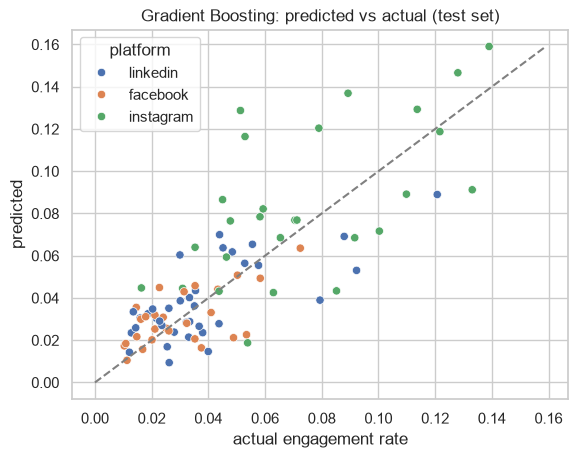

In [7]:
best_name = results.drop("Baseline (platform average)").index[0]
best = fitted[best_name]
print("Best model:", best_name)

# Ranking within each platform (the real use case: comparing drafts for the same platform)
from scipy.stats import spearmanr
pred = best.predict(test[FEATURES])
per_platform = (test.assign(pred=pred).groupby("platform")
                .apply(lambda g: spearmanr(g[TARGET], g["pred"]).statistic, include_groups=False))
print("\nRanking quality (Spearman) within each platform:")
print(per_platform.round(2).to_string())

ax = sns.scatterplot(x=test[TARGET], y=pred, hue=test["platform"])
lim = [0, max(test[TARGET].max(), pred.max())]
ax.plot(lim, lim, "--", color="gray")
ax.set(xlabel="actual engagement rate", ylabel="predicted", title=f"{best_name}: predicted vs actual (test set)")

## 5. What drives engagement?

**Permutation importance:** shuffle one feature at a time and see how much worse the model gets.
A big drop means the model relies on that feature.

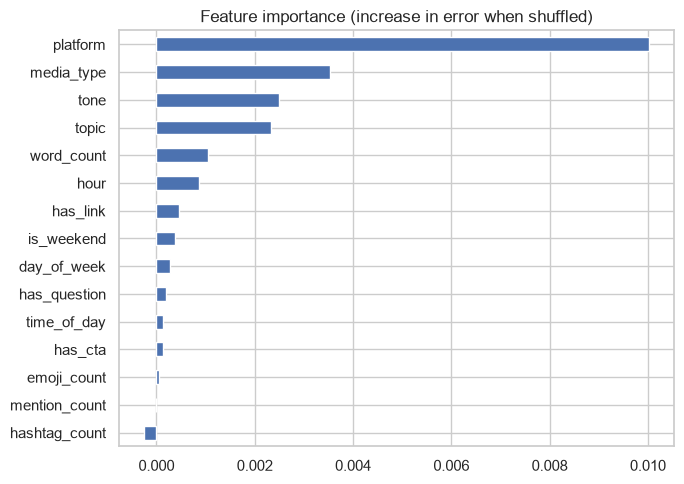

In [8]:
imp = m.feature_importance(best, test)
imp.plot.barh(figsize=(7, 5)).invert_yaxis()
plt.title("Feature importance (increase in error when shuffled)")
plt.tight_layout()

## 6. Insights for the AI writer

These findings get added to the AI's instructions, so new posts follow what has worked for **this** account.
They're saved to `data/processed/insights_prompt.txt` for the writing stage to load.

In [9]:
insights = m.generate_insights(df)
prompt_block = m.insights_to_prompt(insights)
(ROOT / "data/processed/insights_prompt.txt").write_text(prompt_block)
print(prompt_block)

What has worked for this account so far (from past post performance):

Facebook:
- Best media: video (+20% vs average); worst: none (-27%).
- Best topic: tips (+19% vs average); worst: promotion (-30%).
- Best tone: personal (+22% vs average); worst: promotional (-21%).
- Best time of day: evening (+9% vs average); worst: morning (-12%).
- Best day: Wed (+7% vs average); worst: Sun (-21%).
- Posts with a question: +5% engagement vs without.
- Posts with a call to action: +3% engagement vs without.
- Posts with a link in the post: -17% engagement vs without.
- Best hashtag count: 4-6.

Instagram:
- Best media: carousel (+22% vs average); worst: image (-16%).
- Best topic: behind_the_scenes (+30% vs average); worst: promotion (-44%).
- Best tone: personal (+29% vs average); worst: promotional (-39%).
- Best time of day: midday (+17% vs average); worst: morning (-18%).
- Best day: Fri (+25% vs average); worst: Mon (-25%).
- Posts with a question: +17% engagement vs without.
- Posts with a

## 7. Rank AI drafts before review

In the full app, the AI writes several versions of a post and the model picks the most promising ones for your review.
Here are three hand-written LinkedIn drafts for the same idea:

In [10]:
drafts = [
    {"variant": "A: promo + link", "platform": "linkedin", "media_type": "image", "posted_at": "2026-12-01 09:00",
     "text": "Our new social media course is available now! 20% off this week only. Shop now: https://example.com #marketing"},
    {"variant": "B: personal story + question", "platform": "linkedin", "media_type": "carousel", "posted_at": "2026-12-01 09:00",
     "text": "Honestly, I was skeptical about posting every day. I've made every mistake in the book. "
             "Here are the 5 lessons that doubled my reach, step by step. Which one would you try first? #marketing #smallbusiness"},
    {"variant": "C: plain tip, weekend evening", "platform": "linkedin", "media_type": "none", "posted_at": "2026-12-06 20:00",
     "text": "Tip: post consistently. #marketing"},
]
ranked = m.rank_drafts(best, drafts_to_frame(drafts))
ranked[["variant", "media_type", "topic", "tone", "day_of_week", "hour", "predicted_engagement_rate"]].style.format(
    {"predicted_engagement_rate": "{:.2%}"})

,variant,media_type,topic,tone,day_of_week,hour,predicted_engagement_rate
1,B: personal story + question,carousel,tips,personal,Tue,9,10.51%
0,A: promo + link,image,promotion,promotional,Tue,9,3.29%
2,"C: plain tip, weekend evening",none,tips,educational,Sun,20,2.96%


In [11]:
# Best time to post the top draft
top = ranked.iloc[0]
print(f"Best predicted time slots for: {top['variant']}")
m.best_time_slots(best, top).style.format({"predicted_engagement_rate": "{:.2%}"})

Best predicted time slots for: B: personal story + question


,day_of_week,hour,predicted_engagement_rate
1,Fri,11,10.77%
1,Fri,9,10.69%
1,Fri,10,10.68%
1,Tue,9,10.51%
1,Tue,10,10.49%


## 8. Save the model

In [12]:
model_path = ROOT / "models/engagement_model.joblib"
m.save(best, model_path)
results.to_csv(ROOT / "models/model_comparison.csv")
print("saved", model_path.relative_to(ROOT))

saved models/engagement_model.joblib


## Next steps
- **Replace the sample data:** export your real post analytics into `data/raw/`, set `USE_SAMPLE = False`, and re-run.
  With fewer than ~100 real posts, results will be noisy. That's normal; it improves as you post more.
- **Retrain weekly** (`scripts/build_dataset.py`, then re-run this notebook) so the model keeps learning.
- **Better labels:** have the AI tag topic and tone instead of keyword rules (stage 5).
- **Connect to the writer:** load `insights_prompt.txt` and `engagement_model.joblib` in the post-writing step.